In [1]:
%matplotlib inline
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import numpy.ma as ma
import matplotlib.colors as mcolors
from matplotlib.widgets import Slider
import IPython
import math
import boututils
import sys
from boutdata.data import BoutData
from boututils.datafile import DataFile
from matplotlib.colors import Normalize
from matplotlib.cm import ScalarMappable
from matplotlib.ticker import FormatStrFormatter
from boutdata.data import BoutData

FileNotFoundError: [Errno 2] No such file or directory: '/mnt/data/second_profile_initial_plot.png'

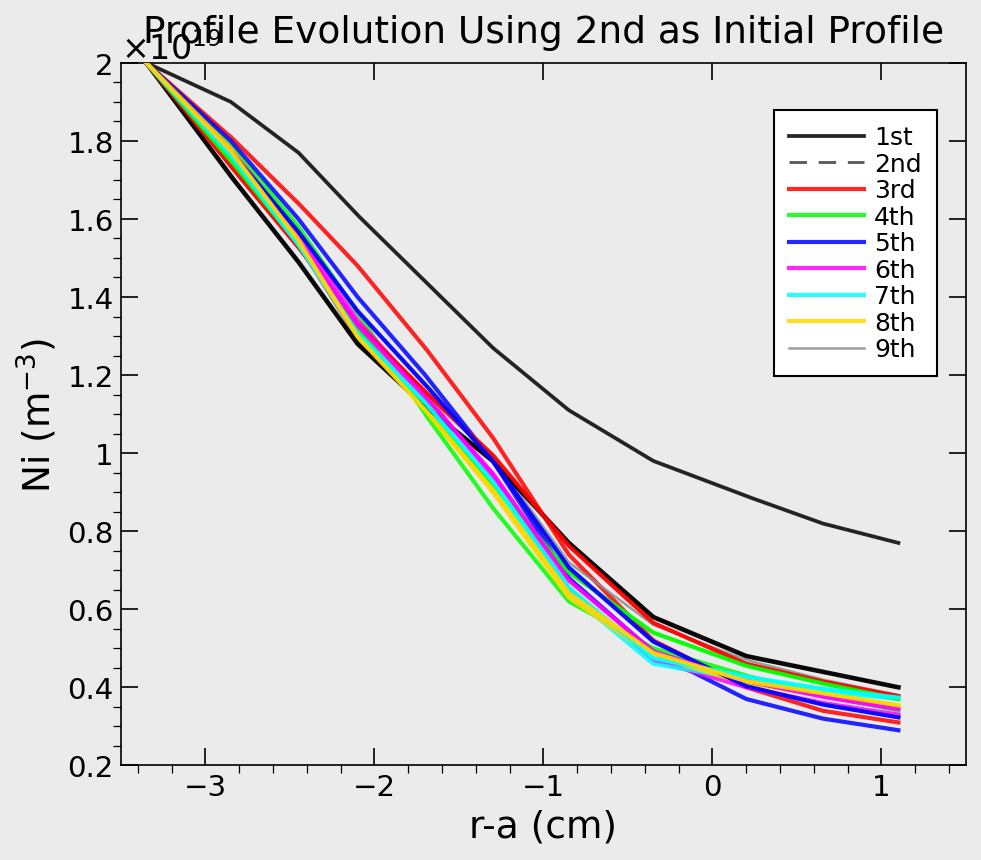

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

# ------------------------------------------------------------
# Hand-estimated profile points chosen to better match the
# reference screenshot. These are still approximations, but they
# follow the visible slopes and relative ordering more closely
# than the original coarse arrays.
# ------------------------------------------------------------

x = np.array([
    -3.35, -2.85, -2.45, -2.10, -1.70, -1.30, -0.85, -0.35, 0.20, 0.65, 1.10
])

profiles = {
    "1st": np.array([2.00, 1.90, 1.77, 1.61, 1.44, 1.27, 1.11, 0.98, 0.89, 0.82, 0.77]) * 1e19,
    "2nd": np.array([2.00, 1.71, 1.49, 1.28, 1.12, 0.98, 0.77, 0.58, 0.48, 0.44, 0.40]) * 1e19,
    "3rd": np.array([2.00, 1.81, 1.64, 1.48, 1.27, 1.04, 0.74, 0.52, 0.40, 0.34, 0.31]) * 1e19,
    "4th": np.array([2.00, 1.79, 1.58, 1.36, 1.10, 0.86, 0.62, 0.50, 0.43, 0.38, 0.34]) * 1e19,
    "5th": np.array([2.00, 1.80, 1.60, 1.40, 1.20, 0.98, 0.68, 0.49, 0.37, 0.32, 0.29]) * 1e19,
    "6th": np.array([2.00, 1.78, 1.56, 1.34, 1.15, 0.94, 0.65, 0.47, 0.40, 0.36, 0.33]) * 1e19,
    "7th": np.array([2.00, 1.77, 1.54, 1.31, 1.13, 0.92, 0.64, 0.46, 0.42, 0.39, 0.37]) * 1e19,
    "8th": np.array([2.00, 1.78, 1.55, 1.30, 1.11, 0.90, 0.63, 0.48, 0.41, 0.38, 0.35]) * 1e19,
    "9th": np.array([2.00, 1.76, 1.53, 1.29, 1.15, 0.99, 0.72, 0.56, 0.47, 0.42, 0.38]) * 1e19,
}

# Styling chosen to match the screenshots
colors = {
    "1st": "k",
    "2nd": "0.25",
    "3rd": "red",
    "4th": "lime",
    "5th": "blue",
    "6th": "magenta",
    "7th": "cyan",
    "8th": "gold",
    "9th": "0.55",
}
linestyles = {
    "1st": "-",
    "2nd": (0, (6, 4)),
    "3rd": "-",
    "4th": "-",
    "5th": "-",
    "6th": "-",
    "7th": "-",
    "8th": "-",
    "9th": "-",
}
linewidths = {k: 2.0 for k in profiles}
linewidths["1st"] = 1.8
linewidths["2nd"] = 1.4
linewidths["9th"] = 1.2

# ------------------------------------------------------------
# Dense x-grid for smoother display and profile blending.
# ------------------------------------------------------------
xd = np.linspace(x.min(), x.max(), 500)

def interp_profile(y):
    return np.interp(xd, x, y)

interp_profiles = {name: interp_profile(y) for name, y in profiles.items()}
p2 = interp_profiles["2nd"]

# Time-ordered family seeded from the second profile and drifting
# toward later profiles. The weights were tuned to keep the family
# visually consistent with the reference trend.
series = [
    ("init = 2nd", p2, "k", "-", 2.2),
    ("t1", 0.75 * interp_profiles["2nd"] + 0.25 * interp_profiles["3rd"], "red", "-", 2.0),
    ("t2", 0.50 * interp_profiles["2nd"] + 0.50 * interp_profiles["4th"], "lime", "-", 2.0),
    ("t3", 0.30 * interp_profiles["2nd"] + 0.70 * interp_profiles["5th"], "blue", "-", 2.0),
    ("t4", 0.20 * interp_profiles["2nd"] + 0.80 * interp_profiles["6th"], "magenta", "-", 2.0),
    ("t5", 0.12 * interp_profiles["2nd"] + 0.88 * interp_profiles["7th"], "cyan", "-", 2.0),
    ("t6", 0.08 * interp_profiles["2nd"] + 0.92 * interp_profiles["8th"], "gold", "-", 2.0),
]

# ------------------------------------------------------------
# Plot
# ------------------------------------------------------------
fig, ax = plt.subplots(figsize=(7.0, 6.2), dpi=150)
fig.patch.set_facecolor("0.92")
ax.set_facecolor("0.92")

# Background reference curves
for name in ["1st", "2nd", "3rd", "4th", "5th", "6th", "7th", "8th", "9th"]:
    ax.plot(
        xd,
        interp_profiles[name],
        color=colors[name],
        linestyle=linestyles[name],
        linewidth=linewidths[name],
        label=name,
        alpha=0.85,
        zorder=1,
    )

# Overlaid evolved curves that explicitly start from the 2nd profile
for label, y, c, ls, lw in series:
    ax.plot(xd, y, color=c, linestyle=ls, linewidth=lw, alpha=0.95, zorder=3)

ax.set_xlim(-3.5, 1.5)
ax.set_ylim(0.2e19, 2.0e19)
ax.set_xlabel("r-a (cm)", fontsize=18)
ax.set_ylabel(r"Ni (m$^{-3}$)", fontsize=18)
ax.tick_params(axis="both", labelsize=14, direction="in", top=True, right=True)

# Make tick labels read 0.2 ... 2 while keeping ×10^19 factor
ax.yaxis.set_major_formatter(FuncFormatter(lambda y, pos: f"{y/1e19:g}"))
ax.text(0.0, 1.005, r"$\times 10^{19}$", transform=ax.transAxes, fontsize=16)

leg = ax.legend(
    loc="upper right",
    frameon=True,
    framealpha=1.0,
    fancybox=False,
    edgecolor="black",
    fontsize=12,
    borderpad=0.6,
    handlelength=3.0,
    handletextpad=0.4,
)
leg.set_bbox_to_anchor((0.98, 0.95))

ax.set_title("Profile Evolution Using 2nd as Initial Profile", fontsize=18, pad=10)
fig.tight_layout()

# Save outputs
fig.savefig("/mnt/data/second_profile_initial_plot.png", bbox_inches="tight")
fig.savefig("/mnt/data/second_profile_initial_plot.pdf", bbox_inches="tight")
plt.show()


In [2]:
def plot_trimmed_matrix(matrix, 
                        masked=True,
                        string="title", 
                        mask_percent=5, 
                        scale="linear",
                        dpi=800,
                        suppress_warnings=False):
    """
    Plots a matrix with the top and bottom `mask_percent` percent of values masked, 
    along with NaNs, and scales the color bar based only on the unmasked values.
    
    Parameters:
        matrix (numpy.ndarray): The input 2D array.
        mask_percent (float): The percentage of extreme values (top and bottom) to mask.
    """
    matrix = np.array(matrix, dtype=np.float64)  # Ensure it's a float array

    # Flattened array without NaNs for percentile calculations
    valid_values = matrix[~np.isnan(matrix)]

    if valid_values.size == 0:
        raise ValueError("Matrix contains only NaNs, nothing to plot.")

    # Calculate percentile thresholds
    lower_bound = np.percentile(valid_values, mask_percent)
    upper_bound = np.percentile(valid_values, 100 - mask_percent)

    # Create a masked array: Mask NaNs and extreme values
    masked_matrix = ma.masked_where(
        ~((matrix < lower_bound) | (matrix > upper_bound) | np.isnan(matrix)), 
        matrix
    )
    
    
    # Define colormap and ensure masked values are distinct
    cmap = plt.cm.viridis
    cmap.set_bad(color='white')  # Set masked areas to white

    # Plot the matrix
    fig, ax = plt.subplots()
    
    nrows, ncols = matrix.shape
    
    # Create x and y coordinate grids
    x = np.arange(ncols + 1)
    y = np.arange(nrows + 1)
      
    norm = mcolors.Normalize(vmin=np.nanmin(matrix), vmax=np.nanmax(matrix))
    ax.set_title(f"{string} computational grid")
    mesh = ax.pcolormesh(x, y, matrix[::-1, :], cmap=cmap, norm=norm, shading='auto')
    
    ax.set_aspect('equal')
    ax.set_title(string)
    # ax.axis('off')

    cbar = fig.colorbar(mesh, ax=ax)
        
    # square plot
    ax.set_aspect(1.0/ax.get_data_ratio(), adjustable='box')
    plt.show()

In [3]:
def plot_time_slices(x, y_values, times=None, cmap='viridis', 
                     xlabel='x', ylabel='y', title='Time Evolution',
                     figsize=(10, 6), colorbar_label='Time', time_axis=0):
    """
    Plot multiple time slices on the same plot with a colorbar indicating time.
    
    Parameters
    ----------
    x : array-like
        The x-axis values (shared across all time slices)
    y_values : list of array-like or 2D array
        The y values for each time slice. Can be:
        - List of 1D arrays, one per time slice
        - 2D array with shape (n_times, n_points) if time_axis=0
        - 2D array with shape (n_points, n_times) if time_axis=1
    times : array-like, optional
        Time values for each slice. If None, uses indices [0, 1, 2, ...]
    cmap : str, optional
        Colormap name (default: 'viridis')
    xlabel : str, optional
        Label for x-axis
    ylabel : str, optional
        Label for y-axis
    title : str, optional
        Plot title
    figsize : tuple, optional
        Figure size (width, height)
    colorbar_label : str, optional
        Label for the colorbar
    time_axis : int, optional
        Which axis represents time in y_values array:
        - 0: shape is (n_times, n_points) - default
        - 1: shape is (n_points, n_times) - (y, t) format
        
    Returns
    -------
    fig, ax : matplotlib figure and axes objects
    
    Examples
    --------
    >>> x = np.linspace(0, 10, 100)
    >>> times = np.linspace(0, 5, 10)
    >>> # Option 1: (time, x) format
    >>> y_values = np.array([np.sin(x - t) for t in times])
    >>> plot_time_slices(x, y_values, times, time_axis=0)
    >>> 
    >>> # Option 2: (y, time) format
    >>> y_values = np.array([np.sin(x - t) for t in times]).T
    >>> plot_time_slices(x, y_values, times, time_axis=1)
    """
    # Convert to numpy array if needed
    y_values = np.array(y_values)
    
    # Transpose if time is on axis 1 to get (n_times, n_points)
    if time_axis == 1:
        y_values = y_values.T
    
    # If times not provided, use indices
    if times is None:
        times = np.arange(len(y_values))
    else:
        times = np.array(times)
    
    # Create figure
    fig, ax = plt.subplots(figsize=figsize)
    
    # Normalize time values for color mapping
    norm = Normalize(vmin=times.min(), vmax=times.max())
    cmap_obj = plt.cm.get_cmap(cmap)
    
    # Plot each time slice
    for i, (y, t) in enumerate(zip(y_values, times)):
        color = cmap_obj(norm(t))
        ax.plot(x, y, color=color, alpha=0.7, linewidth=1.5)
    
    # Add colorbar
    sm = ScalarMappable(cmap=cmap_obj, norm=norm)
    sm.set_array([])
    cbar = plt.colorbar(sm, ax=ax, label=colorbar_label)
    
    # Labels and title
    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)
    ax.set_title(title)
    ax.grid(True, alpha=0.3)
    
    plt.tight_layout()
    return fig, ax

In [4]:
def plot_matrix(matrix, plot_name, masked = False):
    """Plots the matrix using a color plot with a square aspect ratio, handling extreme values."""
    # Mask extreme outliers for better visualization
    percent = 99
    
    # Flatten the array to determine the 10% closest to zero
    flattened = matrix.flatten()
    num_to_keep = int(percent/100 * flattened.size)  # 10% of total elements
    
    # Sort indices based on value (smallest first)
    sorted_indices = np.argsort(flattened)  # Sort in ascending order
    threshold_value = flattened[sorted_indices[num_to_keep - 1]]  # Get the cutoff value
    
    # Mask all values except the lowest 10%
    masked_matrix = np.ma.masked_where(matrix > threshold_value, matrix)
    
    # Define color limits to improve contrast
    vmin = np.percentile(masked_matrix.compressed(), 100-percent)
    vmax = np.percentile(masked_matrix.compressed(), percent)
    
    fig = plt.figure(dpi=800)
    ax = fig.add_subplot()
    if masked:
        plt.imshow(masked_matrix.T, cmap='viridis', interpolation='nearest')#, vmin=vmin, vmax=vmax)
    else:
        plt.imshow(matrix.T, cmap='viridis', interpolation='nearest')
    plt.colorbar(label=r'$Da \ [m^2/s]$')
    plt.title(f"{plot_name}")
    plt.xlabel("ix")
    plt.ylabel("jy")
     
    # square plot
    ax.set_aspect(1.0/ax.get_data_ratio(), adjustable='box')
    plt.show()

In [5]:
from pathlib import Path
from unittest.mock import patch
import matplotlib.pyplot as plt
import sys
sys.path.append("/global/homes/b/btaczak/scripts")
import bout_summarize as bs

def run_bout_summarize(run_dir=None, config=None):
    """
    Run bout_summarize programmatically and return the figures
    for inline display (e.g. in a Jupyter notebook).
    """
    run_dir = Path(run_dir) if run_dir else Path.cwd()
    script_dir = Path(bs.__file__).resolve().parent
    config_path = Path(config) if config else script_dir / "bout_summarize.yaml"

    cfg = bs.load_config(config_path)

    # Force save_figures=False so we get plt.show() calls instead of file writes
    cfg.setdefault("run", {})["save_figures"] = False

    cfg_plot   = cfg.get("plot",      {})
    cfg_data   = cfg.get("data",      {})
    cfg_output = cfg.get("output",    {})
    variables  = cfg.get("variables", [])

    dpi           = cfg_plot.get("dpi",           600)
    cmap          = cfg_plot.get("cmap",          "viridis")
    figsize_scale = cfg_plot.get("figsize_scale", 4)
    t_ind         = cfg_data.get("t_ind",         -1)
    print(t_ind)
    y_ind         = cfg_data.get("y_ind",         "mid")
    z_ind         = cfg_data.get("z_ind",         "mid")

    data_dir_cfg = cfg.get("run", {}).get("data_dir", None)
    data_dir     = (run_dir / data_dir_cfg) if data_dir_cfg else (run_dir / "numpy")

    logger = bs.setup_logging()
    
    dict_2d, dict_1d, psin_cache = {}, {}, {}

    for var_cfg in variables:
        if not var_cfg.get("enabled", True):
            continue

        name        = var_cfg["name"]
        mode        = var_cfg.get("mode", "2d").lower()
        jy_override = var_cfg.get("jy", None)

        display_name, matrix = bs.load_variable(
            data_dir, name, mode, t_ind, y_ind, z_ind,
            jy_override, logger, cfg_output,
        )

        if matrix is None:
            continue

        if mode == "2d":
            dict_2d[display_name] = matrix
        elif mode == "1d":
            jy_used = jy_override if jy_override is not None else (
                int(matrix.shape[0] / 2) if y_ind == "mid" else int(y_ind)
            )
            if jy_used not in psin_cache:
                grid_fname = bs.get_grid_fname(run_dir)
                psin_cache[jy_used] = bs.get_psin_profile(jy_used, grid_fname)
            dict_1d[display_name] = {
                "data": matrix,
                "psin": psin_cache[jy_used],
                "jy":   jy_used,
            }

    figs = {}

    if dict_2d:
        figs["2d"] = bs.plot_variable_matrices(
            dict_2d, dpi=dpi, cmap=cmap, figsize_scale=figsize_scale
        )

    if dict_1d:
        figs["1d"] = bs.plot_variable_lines(
            dict_1d, dpi=dpi, figsize_scale=figsize_scale
        )

    return figs

0


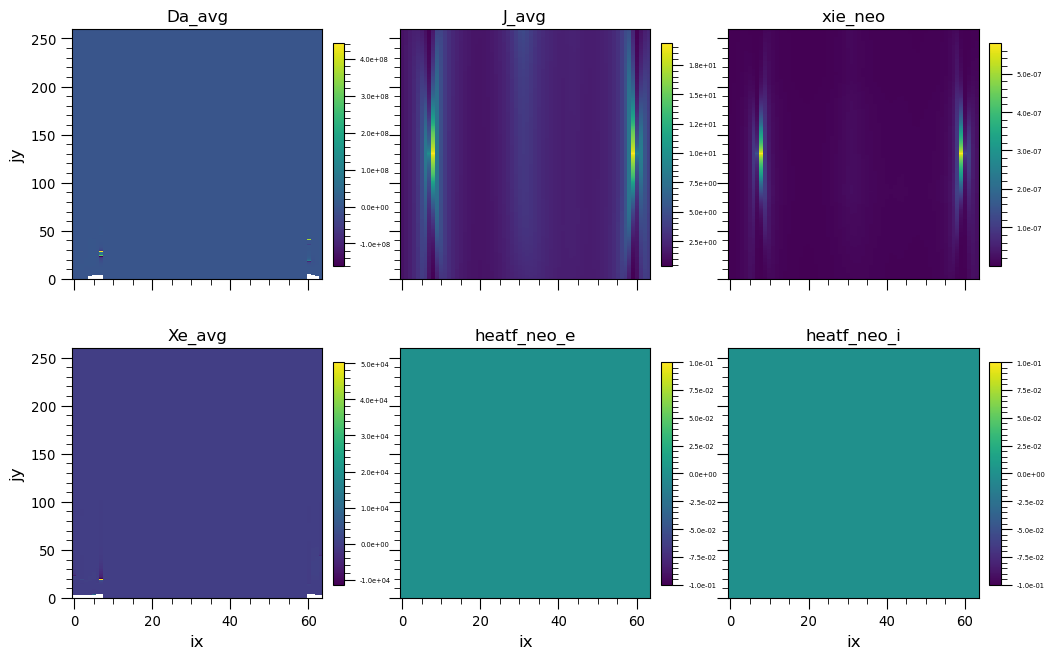

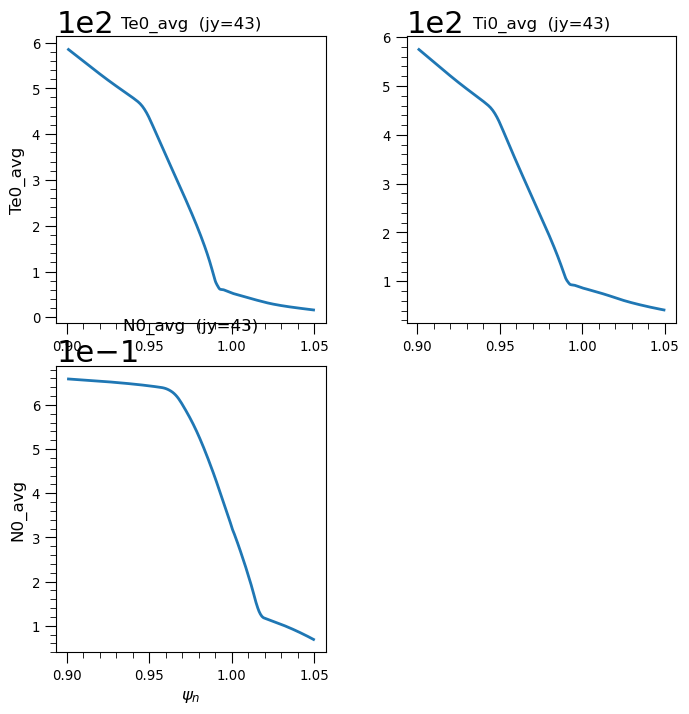

In [6]:
#Shelf_new_grid2_sinks2_gradfix
#Shelf_sbc,Shelf_kefit_nonuniform_a0.2_filters,Shelf_kefit_sq,Shelf_kefit_nonuniform_a0.2_hdv1e,Shelf_kefit_sq_sbc,Shelf_kefit_nonuniform_a0.2_fullsbc_sw1,Shelf_kefit_nonuniform_a0.2_fullsbc,Shelf_kefit_nonuniform_a0.2,Shelf_kefit_nonuniform_a0.2_nocompress
figs = run_bout_summarize(run_dir="/global/cfs/projectdirs/m4491/irvinam/bout-runs/6f-modified/Shelf_kefit_nonuniform_a0.2",config="/global/homes/b/btaczak/scripts/bout_summarize.yaml")
plt.show()

In [7]:
solps_dir = Path("/global/cfs/projectdirs/m4491/btaczak/SIBIL-runs/DIIID_LSN_1D_midplane_diffusion_and_map/NegD_D_1e21_flatstate")
bout_dir  = Path("/global/cfs/projectdirs/m4491/irvinam/bout-runs/6f-modified/Shelf_new_grid2_sinks2_gradfix")
data_dir  = bout_dir / "numpy"
grid_fname= bout_dir / 'd3d_shelf_184016.03200_nc3.grd.nc'
grid_fname = str(grid_fname)
d = BoutData(path=bout_dir)
grid = DataFile(grid_fname)
try:
    _ = grid["psi_bdry"]
    has_psi_bdry = True
except Exception:
    has_psi_bdry = False
    
if has_psi_bdry:
    psi_bndry = grid["psi_bdry"]
else:
    psi_bndry = grid["psi_bndry"]

    
jomp = 44#np.argmax(grid["psixy"][0,:])
psi_midplane = grid["psixy"][:,jomp]
psin_midplane = ((grid["psixy"] - grid["psi_axis"]) / (psi_bndry - grid["psi_axis"]))[:,jomp]

/global/homes/b/btaczak/.conda/envs/bout-data/lib/python3.13/site-packages/boutdata/data.py:765: AlwaysWarning: While building x, y, z coordinate arrays, an exception occured: [Errno 2] No such file or directory: '"d3d_shelf_184016.03200_nc3.grd.nc"'
Evaluating non-scalar options not available
  alwayswarn(


In [8]:
Vr_t = (np.load(data_dir /"Vexbx_txy.npy") + 
        (np.load(data_dir /"Vbtildx_txy.npy")* np.load(data_dir / "Va.npy")))

/tmp/ipykernel_1775002/1110008227.py:69: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap_obj = plt.cm.get_cmap(cmap)


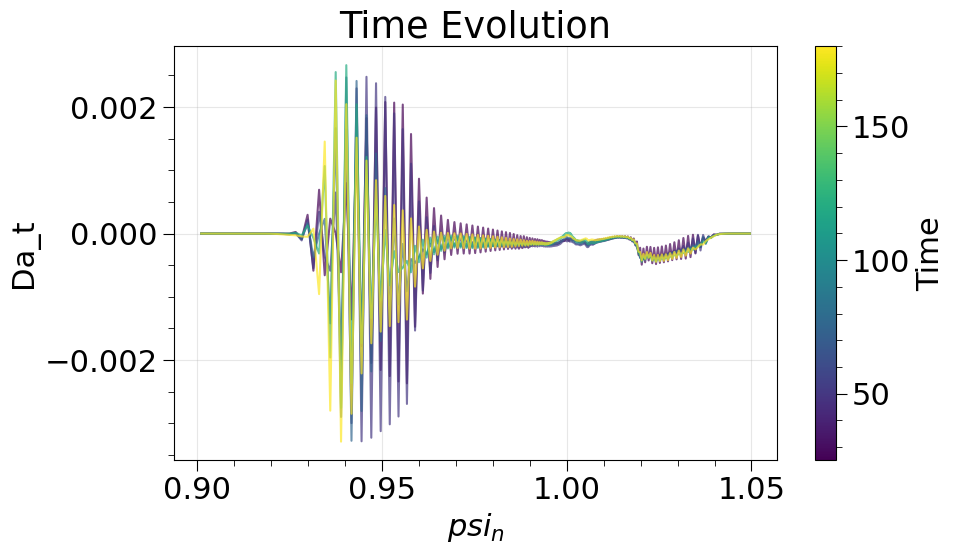

In [15]:
#vars_to_plot_list = ["Da_t", "Vbtildx_txy", "Vexbx_txy"]
vars_to_plot_list = ["Da_t"]#,"ni_txy","ni_txy","Vr_t","Vbtildx_txy", "Vexbx_txy","ddr_nitot_txy","ddr_Tetot_txy","ddr_Titot_txy",]
vars_to_plot = {}
N = 100
l = 190
for var_name in vars_to_plot_list:
    var = np.load(data_dir / f"{var_name}.npy")
    var = np.transpose(var, (1, 2, 0))
    (ix,jy,t_all) = var.shape
    vars_to_plot[var_name] = var[:,:,N:]
    if var_name == "Vexbx_txy":
        vars_to_plot[var_name] = var[:,:,N:]*np.load(data_dir / f"Va.npy")

times = [25,50,75,120,180]
for name, data in vars_to_plot.items():
    y = data[:,jomp,:]
    plot_time_slices(psin_midplane,y,times=times,time_axis=1,xlabel=r'$psi_n$', ylabel=f'{name}')

In [10]:
Ni = np.load(data_dir/"Ni.npy")

In [11]:
Ni.shape

(196, 260, 64, 64)

Da_t
(196, 260, 64)


/tmp/ipykernel_1775002/1110008227.py:69: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap_obj = plt.cm.get_cmap(cmap)


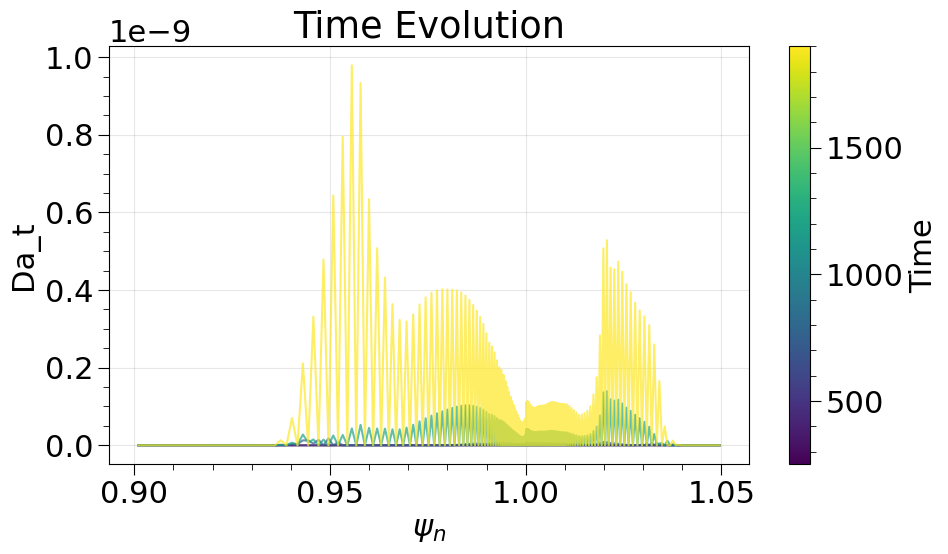

In [19]:
vars_to_plot_list = ["Da_t"]#,"Ni","Vr_t","xie_neo"]
vars_to_plot_averaged = {}
N = 50
l = 100
for var_name in vars_to_plot_list:
    var = np.load(data_dir / f"{var_name}.npy")
    print(var_name)
    print(var.shape)
    if len(var.shape) == 4:
        var = np.sum(var, axis=3) / var.shape[3]
    var = np.transpose(var, (1, 2, 0))
    (ix,jy,t_all) = var.shape
    var_tilde = np.zeros((ix,jy,l))
    for t in range(l):
        if t == 0:
            var_tilde[:,:,0] = var[:,:,0]
        elif l < N:
            if t == 0:
                var_tilde[:,:,t] = var[:,:,0]
            else:
                if var_name == "Da_t":
                    var_tilde[:,:,t] = np.maximum(0,(1/N) * np.sum(var[:,:,:t],axis=2)+((N-l)/N)*var[:,:,(t-1)])
                else:
                    var_tilde[:,:,t] = (1/N) * np.sum(var[:,:,:t],axis=2)+((N-l)/N)*var[:,:,(t-1)]
        elif l >= N:
            if var_name == "Da_t":
                var_tilde[:,:,t] = np.maximum(0,(1/l) * np.sum(var[:,:,:t],axis=2))
            else:
                var_tilde[:,:,t] = (1/l) * np.sum(var[:,:,:t],axis=2)
            
    vars_to_plot_averaged[var_name] = var_tilde

for name, data in vars_to_plot_averaged.items():
    y = data[:,jomp,:]    
    times = [25,50,75,120,190]
    plot_time_slices(psin_midplane,y,times=times,time_axis=1,xlabel=r'$\psi_n$', ylabel=f'{name}')

In [13]:
D_tilde_simple = np.zeros((ix,jy,l)) 
for t in range(l):
    if t == 0:
        D_tilde_simple[:,:,t] = D[:,:,t]
    elif l < N:
        if t == 0:
            D_tilde_simple[:,:,t] = D[:,:,0]
        else:
            D_tilde_simple[:,:,t] = np.maximum(0,(1/N) * np.sum(D[:,:,:t],axis=2)+((N-l)/N)*D[:,:,(t-1)])
    elif l >= N:
        D_tilde_simple[:,:,t] = np.maximum(0,(1/l) * np.sum(D[:,:,:t],axis=2))

D_tilde_relaxation = np.zeros((ix,jy,l)) 
for t in range(l):
    if t == 0:
        D_tilde_relaxation[:,:,t] = D[:,:,t]
    elif l < N:
        print("N > l: LONG TIMESCALE AVERAGING NOT APPLICABLE")
    elif l >= N:
        a = 1-1/N
        A = (1-a)/(1-a**(l+1))
        D_tilde_relaxation[:,:,t] = np.maximum(0,A * np.sum(a**(l-t)*D[:,:,:t],axis=2))
        
D_tilde_check = np.zeros((ix,jy,l)) 
for t in range(l):
    if t == 0:
        D_tilde_check[:,:,t] = D[:,:,t]
    if l < N:
        print("N > l: LONG TIMESCALE AVERAGING NOT APPLICABLE")
    elif l >= N:
        a = 1-1/N
        A = (1-a)/(1-a**(l+1))
        D_tilde_check[:,:,t] = np.multiply(A,D[:,:,t]) + (1-A) * np.maximum(0,A * np.sum(a**(l-t-1)*D[:,:,:t-1],axis=2))

NameError: name 'D' is not defined

In [ ]:
nitot_t = np.load(data_dir/"ni_txy.npy")
ni = np.load(data_dir/"N0.npy")

In [ ]:
var_list = ["Da", "Da_t","Ni","ni_txy","ddr_nitot","ddr_nitot_txy","ddr_Tetot","ddr_Tetot_txy","ddr_Titot","ddr_Titot_txy",]

In [ ]:
def get_bout_2d_vars(var_list,data_dir,z_ind=None,t_ind=-1,verbose=False):
    var_dict = {}
    #z_ind = assumes middle index
    if verbose: print(f"DATA DIR: {data_dir}")
    if verbose: print("Starting variable read")
    for var in var_list:
        var_fname = var + ".npy"
        if verbose: print(f"Reading variable {var} from {var_fname}")
        var_matrix = np.load(data_dir / var_fname)
        if len(var_matrix.shape) == 2:
            var_name = var + "_tavg"
        elif len(var_matrix.shape) == 3:
            var_name = var
            var_matrix = np.transpose(var_matrix, (1, 2, 0))
            var_matrix = var_matrix[:,:,t_ind]
        elif len(var_matrix.shape) == 4:
            var_name = var
            var_matrix = np.transpose(var_matrix, (1, 2, 3, 0))
            if z_ind is not None:
                z_ind = int(var_matrix.shape[2]/2)
            print(f"{var}_kz = {z_ind}")
            var_matrix = var_matrix[:,:,z_ind,t_ind]
        var_dict[var_name] = var_matrix
    return var_dict

Text(0, 0.5, '$D_a \\ [m^2/s]$')

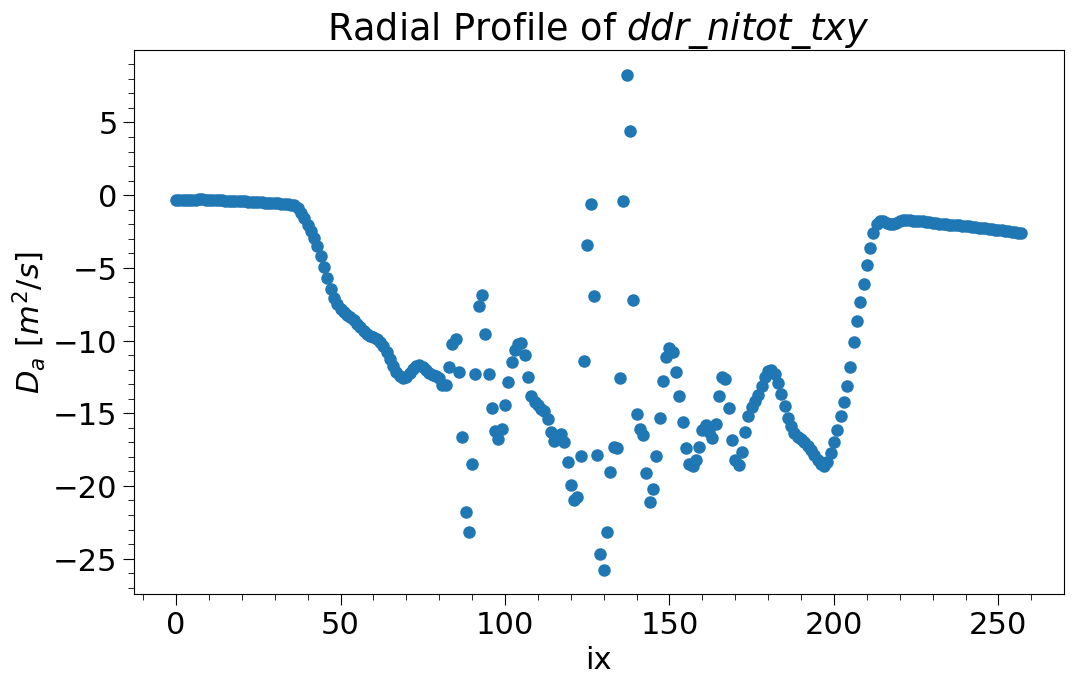

In [17]:
var = np.load(data_dir/"ddr_nitot_txy.npy")
var = np.transpose(var, (1, 2, 0))
fig, ax = plt.subplots()
plt.subplots_adjust(bottom=0.2)
frame = 0
x = np.arange(0,258)
# y_init = D_tilde_simple[:-2,20:-20,-50]
y = var[:-2,-9,-10] #np.sum(y_init,axis=1)
# y = y/y_init.shape[1]
ax.scatter(x,y) # vmin=data.min, vmax=data.max())
ax.set_title(r'Radial Profile of $ddr\_nitot\_txy$')
ax.set_xlabel("ix")
ax.set_ylabel(r'$D_a \ [m^2/s]$')

In [18]:
def load_var(name):
    return np.load(data_dir/f"{name}.npy", mmap_mode="r")

Va = load_var("Va")
Nbar = 1e20

Vr = (load_var("Vexbx_xy") +
      load_var("Vbtildx_xy")) * Va

Vr_t = (load_var("Vexbx_txy") +
        load_var("Vbtildx_txy")) * Va

nitot_xy = load_var("ni_xy")
nitot_txy = load_var("ni_txy")

Da = nitot_xy * Vr / np.gradient(nitot_xy)[0]
Da_t = nitot_txy * Vr_t / np.gradient(nitot_txy)[0]

/tmp/ipykernel_937998/3961193273.py:16: RuntimeWarning: divide by zero encountered in divide
  Da = nitot_xy * Vr / np.gradient(nitot_xy)[0]
/tmp/ipykernel_937998/3961193273.py:16: RuntimeWarning: invalid value encountered in divide
  Da = nitot_xy * Vr / np.gradient(nitot_xy)[0]
/tmp/ipykernel_937998/3961193273.py:17: RuntimeWarning: divide by zero encountered in divide
  Da_t = nitot_txy * Vr_t / np.gradient(nitot_txy)[0]
/tmp/ipykernel_937998/3961193273.py:17: RuntimeWarning: invalid value encountered in divide
  Da_t = nitot_txy * Vr_t / np.gradient(nitot_txy)[0]


In [19]:
# ny = D_tilde_simple.shape[1]
nx = D_tilde_simple.shape[0]
nt = l - N

amplitudes = np.zeros((nx, nt))
for t in range(nt):
    for i in range(nx):
        amplitudes[i, t] = np.nanmean(D_tilde_relaxation[i, :, t+N])
        # amplitudes[i, t] = D_tilde_simple[i,jy_mid,t+N]

# ---- Plot with colorbar ----
import matplotlib.pyplot as plt
import numpy as np

fig, ax = plt.subplots()

# Use the time index as the color
colors = np.arange(nt)

# Loop over t but plot with a single colormap
for t in range(nt):
    sc = ax.scatter(
        np.arange(nx),
        amplitudes[:, t],
        c=np.full(nx, t),             # each point gets color corresponding to t
        cmap="viridis",
        vmin=0, vmax=nt-1,
        s=15
    )

# Add colorbar showing which color corresponds to which t
cbar = plt.colorbar(sc, ax=ax)
cbar.set_label(r"Time index $[t_{'converged'} + 10^{-12}s]$")

ax.set_ylim(ymin=0.0,ymax=0.5)
ax.set_xlabel("Radial Index (ix)")
ax.set_ylabel(r"$\bar{D}_a \ [m^2/s]$")
ax.set_title(r"$\bar{D}_a$ vs $t$")

plt.show()

NameError: name 'D_tilde_relaxation' is not defined

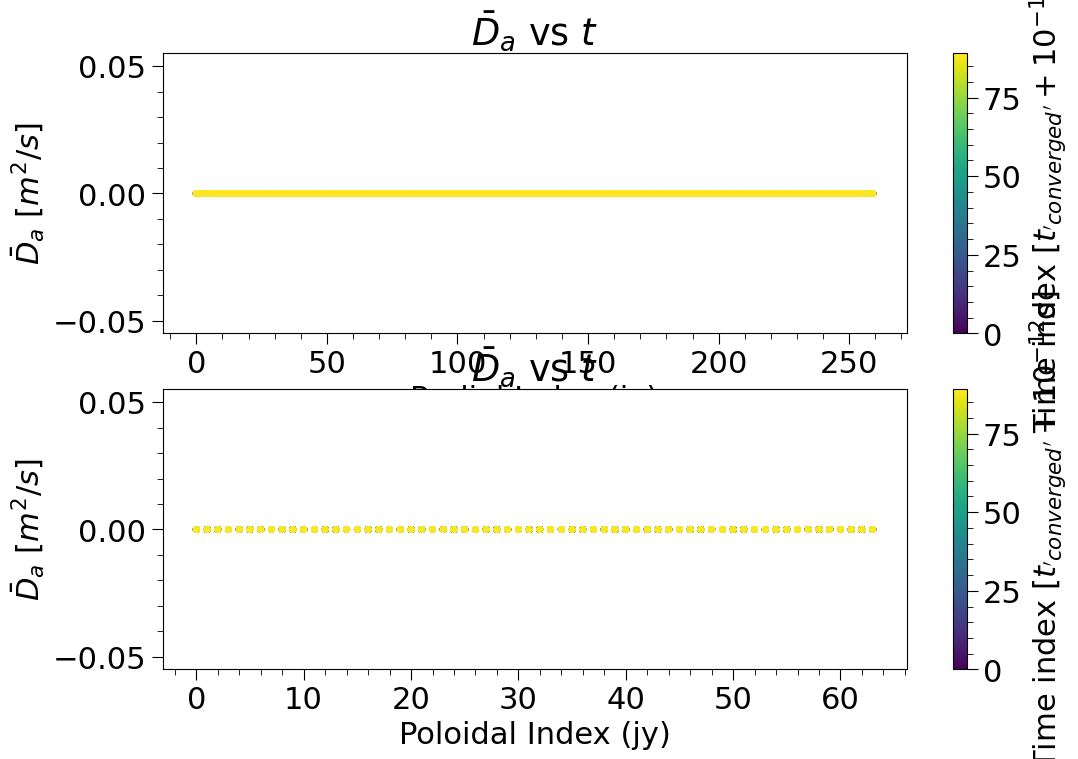

In [20]:
# ny = D_tilde_simple.shape[1]
nx = D_tilde_simple.shape[0]
nt = l - N

amplitudes = np.zeros((nx, nt))
for t in range(nt):
    for i in range(nx):
        amplitudes[i, t] = np.nanmean(D_tilde_simple[i, :, t+N])

fig, axs = plt.subplots(2,1)

# Use the time index as the color
colors = np.arange(nt)

# Loop over t but plot with a single colormap
for t in range(nt):
    sc1 = axs[0].scatter(
        np.arange(nx),
        amplitudes[:, t],
        c=np.full(nx, t),             # each point gets color corresponding to t
        cmap="viridis",
        vmin=0, vmax=nt-1,
        s=15
    )

# Add colorbar showing which color corresponds to which t
cbar1 = plt.colorbar(sc1, ax=axs[0])
cbar1.set_label(r"Time index $[t_{'converged'} + 10^{-12}s]$")

# axs[0].set_ylim(ymin=0.0,ymax=.02)
axs[0].set_xlabel("Radial Index (ix)")
axs[0].set_ylabel(r"$\bar{D}_a \ [m^2/s]$")
axs[0].set_title(r"$\bar{D}_a$ vs $t$")


ny = D_tilde_simple.shape[1]
nt = l - N

amplitudes = np.zeros((ny, nt))
for t in range(nt):
    for i in range(ny):
        amplitudes[i, t] = np.sum(D_tilde_simple[:, i, t+N]) / ny

# Use the time index as the color
colors = np.arange(nt)

# Loop over t but plot with a single colormap
for t in range(nt):
    sc2 = axs[1].scatter(
        np.arange(ny),
        amplitudes[:, t],
        c=np.full(ny, t),             # each point gets color corresponding to t
        cmap="viridis",
        vmin=0, vmax=nt-1,
        s=15
    )

# Add colorbar showing which color corresponds to which t
cbar2 = plt.colorbar(sc2, ax=axs[1])
cbar2.set_label(r"Time index $[t_{'converged'} + 10^{-12}s]$")

axs[1].set_xlabel("Poloidal Index (jy)")
axs[1].set_ylabel(r"$\bar{D}_a \ [m^2/s]$")
axs[1].set_title(r"$\bar{D}_a$ vs $t$")

plt.show()

In [21]:
def get_matrix_plot(ax, matrix, masked = False):
    """Plots the matrix using a color plot with a square aspect ratio, handling extreme values."""
    # Mask extreme outliers for better visualization
    percent = 99
    
    # Flatten the array to determine the 10% closest to zero
    flattened = matrix.flatten()
    num_to_keep = int(percent/100 * flattened.size)  # 10% of total elements
    
    # Sort indices based on value (smallest first)
    sorted_indices = np.argsort(flattened)  # Sort in ascending order
    threshold_value = flattened[sorted_indices[num_to_keep - 1]]  # Get the cutoff value
    
    # Mask all values except the lowest 10%
    masked_matrix = np.ma.masked_where(matrix > threshold_value, matrix)
    
    # Define color limits to improve contrast
    vmin = np.percentile(masked_matrix.compressed(), 100-percent)
    vmax = np.percentile(masked_matrix.compressed(), percent)
    
    if masked:
        ax.imshow(masked_matrix.T, cmap='viridis', interpolation='nearest')#, vmin=vmin, vmax=vmax)
    else:
        ax.imshow(matrix.T, cmap='viridis', interpolation='nearest')
    ax.colorbar(label=r'$Da \ [m^2/s]$')
     
    # square plot
    ax.set_aspect(1.0/ax.get_data_ratio(), adjustable='box')

In [22]:
def plot_variable_matrices(data_dict,
                           dpi=600,
                           cmap="viridis",
                           share_colorbar=False,
                           figsize_scale=4):
    """
    Parameters
    ----------
    data_dict : dict
        Dictionary of {name: 2D numpy array}
    cmap : str
        Matplotlib colormap
    share_colorbar : bool
        If True, use a global color scale
    figsize_scale : float
        Size multiplier for figure
    """

    n_vars = len(data_dict)
    ncols = math.ceil(math.sqrt(n_vars))
    nrows = math.ceil(n_vars / ncols)

    fig, axes = plt.subplots(nrows, ncols,
                             figsize=(figsize_scale*ncols,
                                      figsize_scale*nrows),
                             dpi=dpi
                            )

    # Flatten axes for easy indexing
    axes = np.array(axes).reshape(-1)

    # Determine global min/max if sharing colorbar
    if share_colorbar:
        global_min = min(np.nanmin(arr) for arr in data_dict.values())
        global_max = max(np.nanmax(arr) for arr in data_dict.values())
    else:
        global_min = global_max = None

    for ax, (name, matrix) in zip(axes, data_dict.items()):

        if share_colorbar:
            im = ax.imshow(matrix,
                           cmap=cmap,
                           vmin=global_min,
                           vmax=global_max,
                           origin="lower",
                           interpolation='nearest')
        else:
            im = ax.imshow(matrix,
                           cmap=cmap,
                           origin="lower",
                           interpolation='nearest')

        ax.set_title(name)
        ax.set_xlabel("ix")
        ax.set_ylabel("jy")
        ax.set_aspect(1.0/ax.get_data_ratio(), adjustable='box')
        fig.colorbar(im, ax=ax, shrink=0.8)

    # Turn off unused axes
    for ax in axes[n_vars:]:
        ax.axis("off")

    plt.tight_layout()
    plt.show()

In [23]:
def plot_variable_matrices(
        data_dict,
        dpi=600,
        cmap="viridis",
        figsize_scale=4):

    n_vars = len(data_dict)
    ncols = math.ceil(math.sqrt(n_vars))
    nrows = math.ceil(n_vars / ncols)

    fig_width = figsize_scale * ncols
    fig_height = figsize_scale * nrows

    fig, axes = plt.subplots(
        nrows,
        ncols,
        figsize=(fig_width, fig_height),
        dpi=dpi
    )

    axes = np.atleast_1d(axes).flatten()

    # Auto-scale font size based on figure size
    base_font = max(6, 1.0 * figsize_scale * 3)

    global_min = global_max = None
        
    for idx, (ax, (name, matrix)) in enumerate(zip(axes, data_dict.items())):

        row = idx // ncols
        col = idx % ncols
        
        im = ax.imshow(
            matrix,
            cmap=cmap,
            origin="lower",
            interpolation="nearest"
        )

        # Title scaled
        ax.set_title(name, fontsize=base_font)

        # Show only leftmost y-label
        if col == 0:
            ax.set_ylabel("jy", fontsize=base_font)
        else:
            ax.set_ylabel("")
            ax.set_yticklabels([])

        # Show only bottom x-label
        if row == nrows - 1:
            ax.set_xlabel("ix", fontsize=base_font)
        else:
            ax.set_xlabel("")
            ax.set_xticklabels([])

        # Only show max tick value
        nx = matrix.shape[1]
        ny = matrix.shape[0]

        # ax.set_xticks([nx - 1])
        # ax.set_yticks([ny - 1])

        ax.tick_params(labelsize=base_font * 0.8)

        # Preserve aspect ratio of matrix
        ax.set_aspect(1.0 / ax.get_data_ratio(), adjustable='box')

        cbar = fig.colorbar(im, ax=ax, shrink=0.75,fraction=0.046, pad=0.04)
        cbar.ax.tick_params(labelsize=base_font* 0.4)
        cbar.ax.yaxis.get_offset_text().set_size(base_font * 0.8)
        cbar.ax.yaxis.set_major_formatter(FormatStrFormatter('%1.e'))

    # Turn off unused axes
    for ax in axes[n_vars:]:
        ax.axis("off")

    # plt.tight_layout()
    fig.subplots_adjust(wspace=min(0.2,np.sqrt(0.40/nrows)), hspace=min(0.15/2,0.15/nrows))
    plt.show()

In [24]:
#help(ax.tick_params)

Ni_kz = 32
ddr_nitot_kz = 32
ddr_Tetot_kz = 32
ddr_Titot_kz = 32


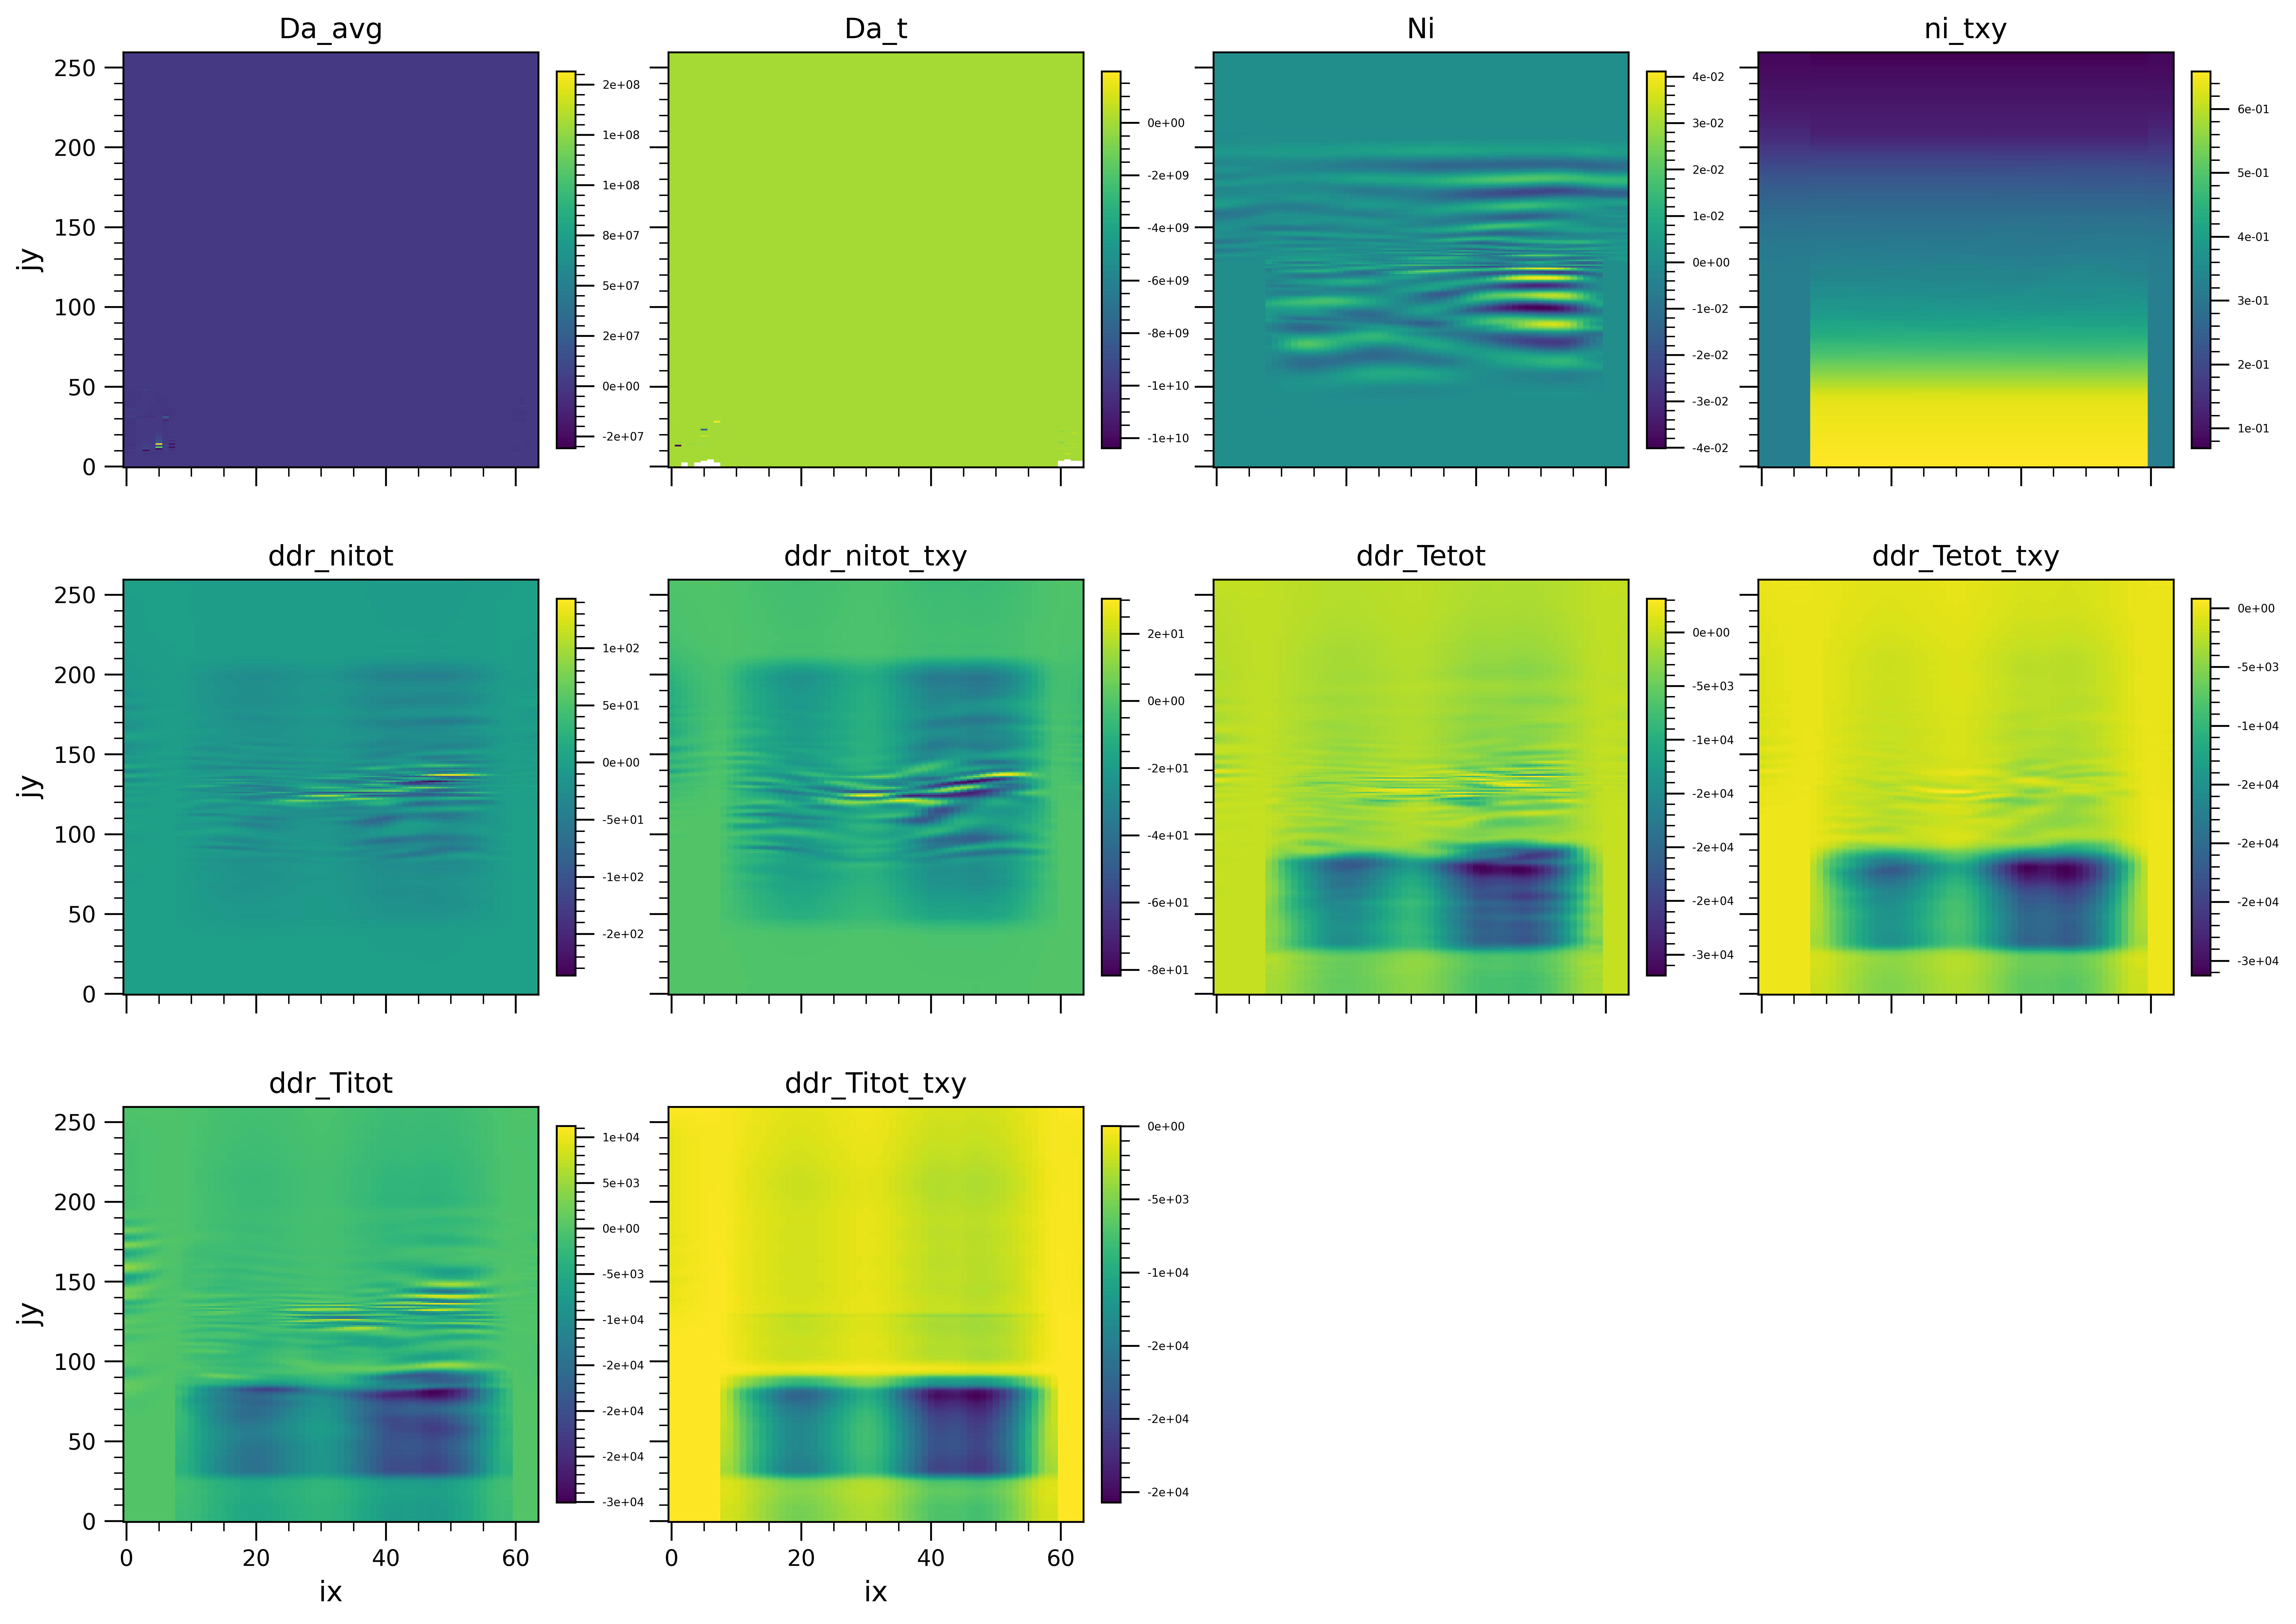

In [25]:
var_list = ["Da", "Da_t","Ni","ni_txy","ddr_nitot","ddr_nitot_txy","ddr_Tetot","ddr_Tetot_txy","ddr_Titot","ddr_Titot_txy",]
var_dict = {}
t_ind = -10
#z_ind = assumes middle index

for var in var_list:
    var_fname = var + ".npy"
    var_matrix = np.load(data_dir / var_fname)
    if len(var_matrix.shape) == 2:
        var_name = var + "_avg"
    elif len(var_matrix.shape) == 3:
        var_name = var
        var_matrix = np.transpose(var_matrix, (1, 2, 0))
        var_matrix = var_matrix[:,:,t_ind]
    elif len(var_matrix.shape) == 4:
        var_name = var
        var_matrix = np.transpose(var_matrix, (1, 2, 3, 0))
        z_ind = int(var_matrix.shape[2]/2)
        print(f"{var}_kz = {z_ind}")
        var_matrix = var_matrix[:,:,z_ind,t_ind]
    var_dict[var_name] = var_matrix

plot_variable_matrices(var_dict)